# Лабораторна робота № 1

## Вхідний аналіз набору даних

**Дисципліна:** Інтелектуальний аналіз та візуалізація даних (СК26)
**Тривалість:** 2 год аудиторно + 3 год самостійної роботи · **Максимальна оцінка:** 4 бали

---

### Мета роботи

Пригадати роботу в Jupyter Notebook, бібліотеці `pandas` та побудову графіків —
і зробити це не на навчальному прикладі, а на реальному файлі, який ніхто не готував
спеціально для вас.

Ця робота виконується **до першої лекції**. Нічого нового знати не потрібно: усе,
що знадобиться, ви вже проходили в попередніх курсах. Усі поняття, яких ви тут
торкнетеся мимохідь, отримають назви й пояснення на лекціях 3 і 4.

### Дані

Файл `20171129_FINAL_FINAL.xlsx`, аркуш `Sheet1` — спостереження космічної погоди
за 28 серпня — 22 вересня 2017 року, зібрані з трьох різних джерел.

Файл видається **як є**, рівно в тому вигляді, у якому його колись вивантажили.
Ніхто не приводив його до ладу, і саме в цьому сенс: справжні дані здебільшого
надходять саме такими.

### Що ви маєте зробити

| Етап | Зміст | Де |
|---|---|---|
| 1 | Розібратися, що взагалі лежить у файлі | аудиторно |
| 2 | Виділити три таблиці й привести їх до робочого вигляду | аудиторно |
| 3 | Скласти паспорт даних: що є, чого бракує, що виглядає дивно | аудиторно |
| 4 | Об'єднати три таблиці в одну | аудиторно |
| 5 | Побудувати п'ять графіків, кожен — відповідь на питання | аудиторно + самостійно |
| 6 | Порівняти два графіки одних і тих самих даних | самостійно |
| 7 | Записати три спостереження про дані | самостійно |
| 8 | Декларація про використання інструментів ШІ | самостійно |

### Що здається

1. Цей файл `.ipynb` із заповненими розв'язками. **Ноутбук має виконуватися згори
   донизу на чистому ядрі** (Kernel → Restart & Run All) без помилок — це перевіряється
   першою дією на захисті.
2. Файл `master_hourly.csv` — об'єднана таблиця з етапу 4.
3. Експорт ноутбука у HTML або PDF.
4. Заповнена декларація (етап 8). Без неї фінальна самоперевірка не проходить.

### Критерії оцінювання

| Бали | Що досягнуто |
|---|---|
| 0 | Дані не опрацьовано, графіки не побудовано або побудовано з грубими помилками |
| 1 | Таблиці прочитано й кілька графіків побудовано, але типи графіків не відповідають даним, дивних значень не помічено |
| 2 | Таблиці розібрано й об'єднано, графіки коректні та підписані, але висновків під ними немає або вони формальні |
| 4 | Усе вище виконано, знайдено й пояснено дивні значення, під кожним графіком є змістовний висновок про дані |

**Головне про оцінку:** бали ставляться не за наявність графіка, а за речення під ним.
Код, який нічого не пояснює, коштує двох балів з чотирьох.

---
## Нагадування про Jupyter

Якщо давно не працювали — три речі, які знадобляться сьогодні:

* `Shift+Enter` виконує клітинку, `Esc` `A` / `Esc` `B` додає клітинку вище / нижче,
  `Esc` `M` перетворює клітинку на текстову (Markdown), `Esc` `Y` — назад на код.
* **Порядок виконання має значення.** Якщо ви правили клітинки в довільному порядку,
  результат може залежати від історії запусків. Перед здачею обов'язково
  **Kernel → Restart & Run All** — так ви побачите ноутбук очима викладача.
* Текстові клітинки — не прикраса. Висновки пишуться в них, а не в коментарях до коду.

---
## Крок 0. Ваші дані та варіант

Заповніть три змінні й виконайте обидві клітинки. Друга надрукує **ваше
індивідуальне завдання** — воно відрізняється від завдання сусіда.

In [1]:
ПІБ = 'Яцишин Роман Олегович'        # напр. 'Шевченко Тарас'
ГРУПА = 'ШІ-32'      # напр. 'КН-31'
ВАРІАНТ = 19     # ваш номер за списком групи

assert ПІБ and ГРУПА and ВАРІАНТ, 'Заповніть ПІБ, ГРУПУ та ВАРІАНТ'

In [2]:
# --- клітинку не редагувати: вона видає ваше персональне завдання ------------
ПОТОКИ = ['P>1', 'P>5', 'P>10', 'P>30', 'P>50', 'P>100', 'E>0.8', 'E>2.0']

ПАРИ = [('швидкість вітру', 'густина вітру'),
        ('швидкість вітру', 'потік P>10'),
        ('густина вітру', 'потік P>1'),
        ('радіопотік F10.7', 'потік P>10'),
        ('радіопотік F10.7', 'швидкість вітру'),
        ('потік E>0.8', 'потік P>10')]

АГРЕГАТИ = ['середнє', 'максимум', 'медіана', 'мінімум']

ПИТАННЯ = [
    'Скільки годин за все вікно ваш потік перевищував своє власне медіанне значення?',
    'У яку добу середнє значення вашого потоку було найбільшим? А найменшим?',
    'О котрій годині доби потік E>0.8 у середньому найбільший? Побудуйте графік середнього за годинами доби.',
    'Яка частка рядків об’єднаної таблиці має пропуск хоча б в одному стовпці?',
    'У який день радіопотік F10.7 був найбільшим і чи збігається цей день з піком вашого потоку?',
    'Порівняйте медіану вашого потоку за перший і за другий тиждень спостережень. У скільки разів вони відрізняються?',
    'Скільки годин поспіль тривала найдовша неперервна серія «активних» годин (група з етапу 4)?',
    'Який зі стовпців об’єднаної таблиці має найбільший розкид відносно власного середнього?',
    'Яку частку сумарного значення вашого потоку за все вікно дали 24 години навколо піку?',
    'Скільки різних діб потрапило у групу «активні» і скільки — у групу «дуже активні»?',
]

i = int(ВАРІАНТ)
завдання = {
    'ваш потік':                      ПОТОКИ[(i * 3 + 1) % 8],
    'ваша пара для графіка 3':        ' та '.join(ПАРИ[(i * 5 + 2) % 6]),
    'ваш агрегат для етапу 4':        АГРЕГАТИ[(i * 5 + 1) % 4],
    'ваше додаткове питання':         ПИТАННЯ[(i * 11 + 5) % 10],
}

print('ІНДИВІДУАЛЬНЕ ЗАВДАННЯ · %s, %s, варіант %d' % (ПІБ, ГРУПА, i))
print('=' * 78)
for k, v in завдання.items():
    print('%-28s %s' % (k + ':', v))

ІНДИВІДУАЛЬНЕ ЗАВДАННЯ · Яцишин Роман Олегович, ШІ-32, варіант 19
ваш потік:                   P>10
ваша пара для графіка 3:     швидкість вітру та потік P>10
ваш агрегат для етапу 4:     середнє
ваше додаткове питання:      У який день радіопотік F10.7 був найбільшим і чи збігається цей день з піком вашого потоку?


Далі за текстом **«ваш потік»** означає стовпець, названий у першому рядку завдання.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 40)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 9})

ФАЙЛ = '20171129_FINAL_FINAL.xlsx'

---
# Етап 1. Що взагалі лежить у файлі

Перше правило роботи з незнайомими даними: спершу подивитися, потім рахувати.

### Завдання 1.1
Спробуйте прочитати аркуш `Sheet1` звичайним способом — `pd.read_excel(ФАЙЛ)` —
і виведіть перші рядки та типи стовпців.

*Очікуваний результат: результат буде дивним. Подивіться на назви стовпців і на
те, які там типи даних. Поясніть у наступній клітинці, чому так вийшло.*

In [4]:
# ВАШ КОД
df0 = pd.read_excel(ФАЙЛ)          # звичайне читання: перший рядок аркуша стає заголовком
print(df0.head())
print()
print(df0.dtypes)


   Unnamed: 0        ftp://ftp.swpc.noaa.gov/pub/lists/particle/ Unnamed: 2 Unnamed: 3 Unnamed: 4 Unnamed: 5 Unnamed: 6 Unnamed: 7 Unnamed: 8 Unnamed: 9 Unnamed: 10 Unnamed: 11 Unnamed: 12  \
0         NaN                                                NaN        NaN        NaN        NaN        NaN        NaN        NaN        NaN        NaN         NaN         NaN         NaN   
1         NaN                :Data_list: 20170901_Gs_part_5m.txt        NaN        NaN        NaN        NaN        NaN        NaN        NaN        NaN         NaN         NaN         NaN   
2         NaN                     :Created: 2017 Sep 02 0011 UTC        NaN        NaN        NaN        NaN        NaN        NaN        NaN        NaN         NaN         NaN         NaN   
3         NaN  # Prepared by the U.S. Dept. of Commerce, NOAA...        NaN        NaN        NaN        NaN        NaN        NaN        NaN        NaN         NaN         NaN         NaN   
4         NaN  # Please send comments an

**Відповідь 1.1:** `read_excel` без параметрів бере перший рядок аркуша як заголовок. Там лише один URL, тому назви стовпців вийшли «Unnamed: N», а майже всі типи — `object`. В аркуші кілька таблиць поруч зі службовим текстом над даними, тому pandas не знаходить справжніх заголовків і змішує текст із числами.

### Завдання 1.2
Прочитайте аркуш ще раз, але **без заголовка**: `pd.read_excel(ФАЙЛ, header=None)`.
Виведіть його розмір і подивіться на перші 30 рядків.

In [5]:
# ВАШ КОД
RAW = pd.read_excel(ФАЙЛ, header=None)
print('розмір:', RAW.shape)
print(RAW.head(30).to_string(max_colwidth=30))


розмір: (7226, 32)
    0                              1    2    3     4         5        6      7      8      9       10      11      12     13     14  15                             16     17    18               19  20  21  22  23   24   25                             26   27   28   29     30       31
0  NaN  ftp://ftp.swpc.noaa.gov/pu...  NaN  NaN   NaN       NaN      NaN    NaN    NaN    NaN     NaN     NaN     NaN    NaN    NaN NaN                            NaN    NaN   NaN              NaN NaN NaN NaN NaN  NaN  NaN   http://umtof.umd.edu/pm/crn/  NaN  NaN  NaN    NaN      NaN
1  NaN                            NaN  NaN  NaN   NaN       NaN      NaN    NaN    NaN    NaN     NaN     NaN     NaN    NaN    NaN NaN                            NaN    NaN   NaN              NaN NaN NaN NaN NaN  NaN  NaN                            NaN  NaN  NaN  NaN    NaN      NaN
2  NaN  :Data_list: 20170901_Gs_pa...  NaN  NaN   NaN       NaN      NaN    NaN    NaN    NaN     NaN     NaN     NaN    NaN  

### Завдання 1.3
Для кожного стовпця порахуйте, скільки в ньому заповнених клітинок
(`RAW.notna().sum()`), і виведіть результат.

*Очікуваний результат: 32 числа. Серед них будуть нулі та згустки великих значень.
За цими згустками видно, що в аркуші **не одна таблиця, а кілька**, вставлені поруч.*

**Питання:** скільки таблиць в аркуші і які стовпці займає кожна?

In [6]:
# ВАШ КОД
filled = RAW.notna().sum()
print(filled.to_string())
print('\nвсього стовпців:', len(filled))


0        0
1     7223
2     7202
3     7202
4     7202
5     7203
6     7203
7     7198
8     7198
9     7198
10    7198
11    7198
12    7198
13    7198
14    7198
15       0
16      32
17      26
18      26
19      26
20       0
21       0
22       0
23       0
24     601
25     601
26     608
27     602
28     602
29     602
30     602
31     602

всього стовпців: 32


**Відповідь 1.3:** В аркуші **3 таблиці**: A — стовпці B–O (14 стовпців), B — стовпці Q–T (4), C — стовпці Y–AF (8). Стовпці A, P і U–X порожні: це проміжки між таблицями. Різні «згустки» чисел (≈7200, ≈25, ≈600) відповідають різним кроком у часі: 5 хвилин, доба, година.

### Завдання 1.4
Над кожною таблицею є кілька текстових рядків — це службовий опис від тих, хто дані
збирав. Виведіть їх і випишіть для кожної таблиці **джерело даних та одиниці
вимірювання**.

*Це найкорисніші п'ять хвилин роботи: жодної з цих відомостей у самій таблиці немає,
і без них ви не знатимете, у чому вимірюєте.*

In [7]:
# ВАШ КОД
# службові рядки лежать над даними кожної таблиці (нумерація рядків — з нуля)
meta_text = {
    'A': RAW.iloc[:26, 1:15],
    'B': RAW.iloc[:27, 16:20],
    'C': RAW.iloc[:27, 26:32],
}
for name, block in meta_text.items():
    print('=' * 78)
    print('Таблиця', name)
    for r in block.index:
        line_text = ' | '.join(str(v).strip() for v in block.loc[r].dropna())
        if line_text:
            print('%2d: %s' % (r, line_text))


Таблиця A
 0: ftp://ftp.swpc.noaa.gov/pub/lists/particle/
 2: :Data_list: 20170901_Gs_part_5m.txt
 3: :Created: 2017 Sep 02 0011 UTC
 4: # Prepared by the U.S. Dept. of Commerce, NOAA, Space Weather Prediction Center
 5: # Please send comments and suggestions to SWPC.Webmaster@noaa.gov
 6: #
 7: # Label: P > 1 = Particles at >1 Mev
 8: # Label: P > 5 = Particles at >5 Mev
 9: # Label: P >10 = Particles at >10 Mev
10: # Label: P >30 = Particles at >30 Mev
11: # Label: P >50 = Particles at >50 Mev
12: # Label: P>100 = Particles at >100 Mev
13: # Label: E>0.8 = Electrons at >0.8 Mev
14: # Label: E>2.0 = Electrons at >2.0 Mev
15: # Label: E>4.0 = Electrons at >4.0 Mev
16: # Units: Particles = Protons/cm2-s-sr
17: # Units: Electrons = Electrons/cm2-s-sr
18: # Source: GOES-15
19: # Location: W135
20: # Missing data: -1.00e+05
22: 5-minute  GOES-15 Solar Particle and Electron Flux
23: Modified | Seconds
24: # UT | C D | ate | Time | Julian | of the
25: # YR | MO | DA | HHMM | Day | Day | P > 

**Відповідь 1.4:**

| Таблиця | Джерело | Одиниці вимірювання |
|---|---|---|
| A | NOAA SWPC, супутник GOES-15 (W135), 5-хвилинні дані потоків частинок | протони та електрони: частинок/(см²·с·ср); пропуск позначено −1.00e+05 |
| B | NOAA SWPC, Daily Solar Data (2017Q3_DSD), щоденний радіопотік Сонця F10.7 | у файлі одиниці не вказано |
| C | SOHO CELIAS Proton Monitor (umtof.umd.edu), годинні середні параметри сонячного вітру | швидкість — км/с, густина — протонів/см³ |


---
# Етап 2. Три таблиці в робочому вигляді

У файлі три таблиці. Ось що в них лежить — решту ви вже знайшли самі:

| Таблиця | Стовпці аркуша | Що це | Один рядок = |
|---|---|---|---|
| A | B–O | вимірювання із супутника GOES-15: потоки частинок різної енергії | 5 хвилин |
| B | Q–T | добовий показник сонячної активності F10.7 | доба |
| C | Y–AF | швидкість і густина сонячного вітру | година |

### Завдання 2.1
Виділіть кожну таблицю в окремий `DataFrame` — назвіть їх `A`, `B` і `C`.
Дайте стовпцям осмислені назви й перетворіть значення на числа
(`pd.to_numeric(..., errors='coerce')` стане в пригоді).

In [8]:
# ВАШ КОД
# Положення таблиць в аркуші (нумерація з нуля):
#   A — стовпці B–O  (1..14), дані починаються з рядка 26
#   B — стовпці Q–T  (16..19), заголовок у рядку 26, дані з рядка 27
#   C — стовпці Y–AF (24..31): перші два — службовий лічильник, потрібні 26..31
A = RAW.iloc[26:, 1:15].dropna(how='all').copy()
A.columns = ['YR', 'MO', 'DA', 'HHMM', 'MJD', 'sec',
             'P>1', 'P>5', 'P>10', 'P>30', 'P>50', 'P>100', 'E>0.8', 'E>2.0']

B = RAW.iloc[27:, 16:20].dropna(how='all').copy()
B.columns = ['YR', 'MO', 'DA', 'F107']

C = RAW.iloc[27:, 26:32].dropna(how='all').copy()
C.columns = ['YR', 'MO', 'DA', 'HH', 'speed', 'density']

# усе в числа; те, що не читається, стане NaN
A, B, C = [tbl.apply(pd.to_numeric, errors='coerce').reset_index(drop=True) for tbl in (A, B, C)]

# у службовому описі таблиці A: «Missing data: -1.00e+05»
A = A.replace(-1e5, np.nan)


### Завдання 2.2
У кожній таблиці дата й час записані **по-різному** й розкидані по кількох стовпцях.
Зберіть для кожної таблиці один стовпець `ts` типу `datetime`.

Після цього обов'язково виведіть для кожної таблиці найранішу й найпізнішу дату.

*Очікуваний результат: усі три таблиці мають лежати в межах серпня–вересня 2017 року.
Якщо у вас вийшов інший рік — придивіться, як записано рік у тій таблиці, і виправте.*

In [9]:
# ВАШ КОД
# A: дата в YR/MO/DA, час — одним числом HHMM (напр. 1305 = 13:05)
A.insert(0, 'ts', pd.to_datetime(dict(year=A['YR'], month=A['MO'], day=A['DA']))
         + pd.to_timedelta(A['HHMM'] // 100, unit='h')
         + pd.to_timedelta(A['HHMM'] % 100, unit='min'))

# B: тільки дата, час відсутній (одна доба = один рядок)
B.insert(0, 'ts', pd.to_datetime(dict(year=B['YR'], month=B['MO'], day=B['DA'])))

# C: рік записано двома цифрами (17), тому додаємо 2000; година — окремий стовпець
C.insert(0, 'ts', pd.to_datetime(dict(year=2000 + C['YR'], month=C['MO'], day=C['DA']))
         + pd.to_timedelta(C['HH'], unit='h'))

for name, tbl in [('A', A), ('B', B), ('C', C)]:
    print(name, '· найраніше:', tbl['ts'].min(), '· найпізніше:', tbl['ts'].max())


A · найраніше: 2017-08-28 00:00:00 · найпізніше: 2017-09-21 23:55:00
B · найраніше: 2017-08-28 00:00:00 · найпізніше: 2017-09-21 00:00:00
C · найраніше: 2017-08-28 00:00:00 · найпізніше: 2017-09-22 00:00:00


**Самоперевірка етапу 2.** Клітинка має виконатися без помилок.

In [10]:
assert len(A) == 7200, 'у таблиці A має бути 7200 рядків, а є %d' % len(A)
assert len(B) == 25,   'у таблиці B має бути 25 рядків, а є %d' % len(B)
assert len(C) == 601,  'у таблиці C має бути 601 рядок, а є %d' % len(C)
for назва, т in [('A', A), ('B', B), ('C', C)]:
    рік = pd.to_datetime(т['ts']).dt.year
    assert рік.min() == 2017 and рік.max() == 2017, 'у таблиці %s рік не 2017 — перевірте збирання дати' % назва
print('Етап 2 пройдено')

Етап 2 пройдено


---
# Етап 3. Паспорт даних

### Завдання 3.1
Для кожної таблиці виведіть: розмір, типи стовпців, кількість пропусків у кожному
стовпці, кількість повних дублікатів рядків і описові статистики (`describe()`).

In [11]:
# ВАШ КОД
for name, tbl in [('A', A), ('B', B), ('C', C)]:
    print('=' * 78)
    print('Таблиця', name, '· розмір', tbl.shape)
    print('\nТипи стовпців:')
    print(tbl.dtypes.to_string())
    print('\nПропуски по стовпцях:')
    print(tbl.isna().sum().to_string())
    print('\nПовних дублікатів рядків:', tbl.duplicated().sum())
    print('\ndescribe():')
    print(tbl.drop(columns='ts').describe().T.to_string())
    print()


Таблиця A · розмір (7200, 15)

Типи стовпців:
ts       datetime64[us]
YR                int64
MO                int64
DA                int64
HHMM              int64
MJD               int64
sec               int64
P>1             float64
P>5             float64
P>10            float64
P>30            float64
P>50            float64
P>100           float64
E>0.8           float64
E>2.0           float64

Пропуски по стовпцях:
ts       0
YR       0
MO       0
DA       0
HHMM     0
MJD      0
sec      0
P>1      3
P>5      3
P>10     3
P>30     3
P>50     3
P>100    3
E>0.8    3
E>2.0    3

Повних дублікатів рядків: 0

describe():
        count          mean           std         min         25%         50%         75%       max
YR     7200.0   2017.000000      0.000000   2017.0000   2017.0000   2017.0000    2017.000    2017.0
MO     7200.0      8.840000      0.366632      8.0000      9.0000      9.0000       9.000       9.0
DA     7200.0     13.960000      8.775483      1.0000      7.000

### Завдання 3.2 — дивні значення
Подивіться на рядок `min` у таблиці `describe()` для таблиці C.

Швидкість і густина — фізичні величини, які **не можуть бути від'ємними**.
Знайдіть від'ємні значення, порахуйте, скільки їх, і поверніться до службового опису
з завдання 1.4: там написано, що вони означають.

Замініть ці значення на `NaN` і покажіть, як після цього змінилися середнє й мінімум.

*Очікуваний результат: два числа «до» і «після» для кожного зі стовпців.*

In [12]:
# ВАШ КОД
cols_C = ['speed', 'density']

neg_mask = C[cols_C] < 0
print('від’ємних значень по стовпцях:', neg_mask.sum().to_dict())
print('рядків з від’ємним значенням:', int(neg_mask.any(axis=1).sum()))
print(C.loc[neg_mask.any(axis=1), ['ts'] + cols_C].to_string())

before = C[cols_C].agg(['mean', 'min'])
C[cols_C] = C[cols_C].mask(C[cols_C] < 0)      # від’ємне -> NaN
after = C[cols_C].agg(['mean', 'min'])

print('\nДо та після заміни на NaN:')
print(pd.concat({'до': before, 'після': after}, axis=1).round(2).to_string())


від’ємних значень по стовпцях: {'speed': 8, 'density': 8}
рядків з від’ємним значенням: 8
                     ts  speed  density
175 2017-09-04 07:00:00     -1     -1.0
176 2017-09-04 08:00:00     -1     -1.0
177 2017-09-04 09:00:00     -1     -1.0
178 2017-09-04 10:00:00     -1     -1.0
179 2017-09-04 11:00:00     -1     -1.0
180 2017-09-04 12:00:00     -1     -1.0
181 2017-09-04 13:00:00     -1     -1.0
182 2017-09-04 14:00:00     -1     -1.0

До та після заміни на NaN:
          до           після        
       speed density   speed density
mean  506.55    2.91  513.39    2.96
min    -1.00   -1.00  277.00    0.10


**Відповідь 3.2:** Це значення `-1` у стовпцях `speed` і `density`: по 8 штук, в одних і тих самих 8 рядках (4 вересня з 07:00 до 14:00). Швидкість і густина не бувають від’ємними, тому це маркер пропуску (у службовому описі таблиці C його не пояснено, тож це моє припущення). Вони тягли середнє вниз: середня швидкість змінилась з 506,55 на 513,39 км/с, густина з 2,91 на 2,96, а мінімуми з −1 на 277 км/с і 0,10.

### Завдання 3.3 — питання на подумати
У таблиці A є стовпці, для яких `describe()` слухняно рахує середнє й стандартне
відхилення, хоча ці числа не мають жодного сенсу.

Знайдіть їх і поясніть своїми словами, чому середнє для них безглузде.

*Підказка: не кожне число в таблиці є результатом вимірювання.*

> Це питання не має однієї «правильної» відповіді з підручника — на нього ви
> відповідаєте з власного здорового глузду. Формальне пояснення буде на лекції 3.

In [13]:
# ВАШ КОД
time_cols = ['YR', 'MO', 'DA', 'HHMM', 'MJD', 'sec']
print(A[time_cols].describe().T[['mean', 'std', 'min', 'max']].to_string())


          mean           std      min      max
YR     2017.00      0.000000   2017.0   2017.0
MO        8.84      0.366632      8.0      9.0
DA       13.96      8.775483      1.0     31.0
HHMM   1177.50    692.481902      0.0   2355.0
MJD   58005.00      7.211603  57993.0  58017.0
sec   43050.00  24943.113498      0.0  86100.0


**Відповідь 3.3:** Це службові стовпці `YR`, `MO`, `DA`, `HHMM`, `MJD`, `sec` (рік, місяць, день, час, юліанський день, секунди доби). Вони кодують момент часу, а не вимірюють величину, тому середнє від них (наприклад, ≈1177 для HHMM) нічого не означає.

---
# Етап 4. Об'єднання трьох таблиць в одну

Таблиці мають різний крок у часі: 5 хвилин, година і доба. Щоб працювати з ними
разом, потрібна спільна сітка. Беремо **годину**.

Кожна таблиця потребує своєї дії:

1. **A: 5 хвилин → година.** Кілька рядків згортаються в один — це `resample` + агрегація.
2. **C: уже година.** Просте з'єднання по спільному стовпцю `ts` — `merge`.
3. **B: доба → година.** Навпаки, одне значення розтягується на 24 години доби.

### Завдання 4.1
Зведіть таблицю A до погодинної сітки. Для кожного потоку порахуйте **два** числа
за годину: середнє і максимум.

In [14]:
# ВАШ КОД
# ПОТОКИ задано на початку ноутбука: 'P>1', ..., 'E>2.0'
A_hr = A.set_index('ts')[ПОТОКИ].resample('60min').agg(['mean', 'max'])
A_hr.columns = ['%s_%s' % (col, agg) for col, agg in A_hr.columns]
A_hr = A_hr.reset_index()

print('розмір:', A_hr.shape)
print(A_hr.head().to_string())


розмір: (600, 17)
                   ts  P>1_mean  P>1_max  P>5_mean  P>5_max  P>10_mean  P>10_max  P>30_mean  P>30_max  P>50_mean  P>50_max  P>100_mean  P>100_max    E>0.8_mean  E>0.8_max   E>2.0_mean  E>2.0_max
0 2017-08-28 00:00:00  9.778333    19.40  0.324917    0.690   0.192917     0.314   0.098850    0.2240   0.077583    0.1780    0.040692     0.0793  20941.666667    23600.0  1011.583333     1180.0
1 2017-08-28 01:00:00  7.994167    13.60  0.291667    0.512   0.156583     0.259   0.072583    0.0919   0.058700    0.0798    0.029950     0.0471  18091.666667    20600.0   713.000000      907.0
2 2017-08-28 02:00:00  6.099167    10.80  0.283000    0.479   0.177667     0.321   0.084450    0.1210   0.069642    0.1110    0.035025     0.0595  14108.333333    15000.0   380.833333      475.0
3 2017-08-28 03:00:00  4.752500     7.76  0.236833    0.329   0.166333     0.244   0.087658    0.1800   0.068092    0.1390    0.035517     0.0818  12766.666667    13100.0   267.916667      284.0
4 2017-

### Завдання 4.2
У вашому завданні названо агрегат (`середнє`, `максимум`, `медіана` або `мінімум`).

Візьміть ваш потік за одну добу, порахуйте для нього по годинах ваш агрегат і ще один
на ваш вибір, і побудуйте обидві криві на одному графіку.

**Питання:** чим вони відрізняються і в якій ситуації різниця між ними стане суттєвою?

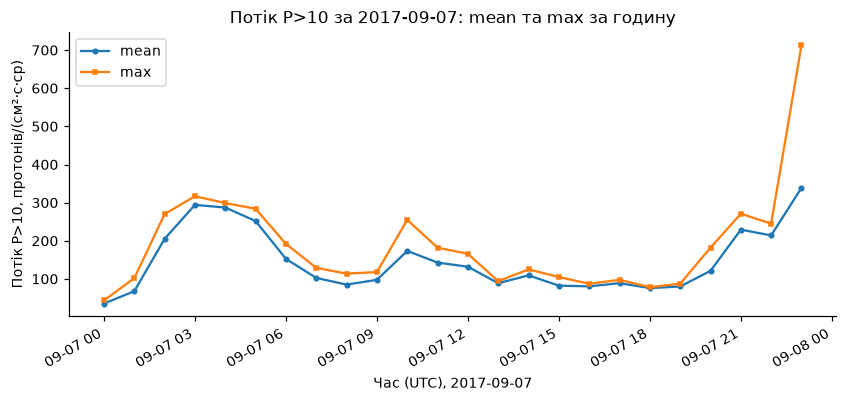

доба з найбільшою розбіжністю: 2017-09-07
найбільша різниця за годину: 373.9 (2017-09-07 23:00:00)
на цій добі max / mean: до 2.1 рази
медіана відношення за весь період: 1.50


In [15]:
# ВАШ КОД
AGG_MAP = {'середнє': 'mean', 'максимум': 'max', 'медіана': 'median', 'мінімум': 'min'}
flux = завдання['ваш потік']
my_agg = AGG_MAP[завдання['ваш агрегат для етапу 4']]
other_agg = 'max' if my_agg != 'max' else 'mean'

# обидва агрегати по годинах за весь період, з 5-хвилинної таблиці A
both = A.set_index('ts')[flux].resample('60min').agg([my_agg, other_agg])

# беремо добу, де розбіжність між агрегатами найбільша — там різницю найкраще видно
gap = (both[other_agg] - both[my_agg]).abs()
day_x = gap.idxmax().normalize()
hourly = both.loc[day_x: day_x + pd.Timedelta(hours=23)]

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(hourly.index, hourly[my_agg], marker='o', ms=3, label=my_agg)
ax.plot(hourly.index, hourly[other_agg], marker='s', ms=3, label=other_agg)
ax.set_xlabel('Час (UTC), %s' % day_x.date())
ax.set_ylabel('Потік %s, протонів/(см²·с·ср)' % flux)
ax.set_title('Потік %s за %s: %s та %s за годину' % (flux, day_x.date(), my_agg, other_agg))
ax.legend()
fig.autofmt_xdate()
plt.show()

ratio = both[other_agg] / both[my_agg]
print('доба з найбільшою розбіжністю:', day_x.date())
print('найбільша різниця за годину: %.1f (%s)' % (gap.max(), gap.idxmax()))
print('на цій добі %s / %s: до %.1f рази' % (other_agg, my_agg, ratio.loc[hourly.index].max()))
print('медіана відношення за весь період: %.2f' % ratio.median())


**Відповідь 4.2:** Максимум за годину завжди не менший за середнє. Зазвичай відношення ≈1,5 (медіана), а 7 вересня о 23:00 максимум 713 проти середнього 339, тобто до 2,1 раза. Різниця стає суттєвою, коли потік різко змінюється всередині години (початок бурі, короткі сплески): середнє тоді згладжує пік, а для оцінки радіаційного ризику важливий саме максимум.

### Завдання 4.3
Об'єднайте три таблиці в одну — назвіть її `M`. Виведіть її розмір і всі рядки,
у яких є хоча б один пропуск.

**Зверніть увагу:** таблиці закінчуються не в один і той самий момент. Тому результат
залежить від того, який тип об'єднання ви оберете (`how='inner'` чи `how='outer'`).
Спробуйте обидва, подивіться, чим відрізняється кількість рядків, і поясніть свій вибір.

In [16]:
# ВАШ КОД
C_hr = C[['ts', 'speed', 'density']]

M_inner = A_hr.merge(C_hr, on='ts', how='inner')
M_outer = A_hr.merge(C_hr, on='ts', how='outer')
print('inner:', len(M_inner), 'рядків · outer:', len(M_outer), 'рядків')
print('\nГодини, які є тільки в outer:')
print(M_outer[~M_outer['ts'].isin(M_inner['ts'])].to_string())

# обираємо outer: не губимо години, де є дані хоча б з однієї таблиці
M = M_outer.sort_values('ts').reset_index(drop=True)

# B: доба -> година. Кожну годину з'єднуємо зі значенням тієї доби, до якої вона належить
M['day'] = M['ts'].dt.normalize()
M = M.merge(B[['ts', 'F107']].rename(columns={'ts': 'day'}), on='day', how='left').drop(columns='day')

print('\nрозмір M:', M.shape)
print('\nРядки хоча б з одним пропуском:')
print(M[M.isna().any(axis=1)].to_string())


inner: 600 рядків · outer: 601 рядків

Години, які є тільки в outer:
            ts  P>1_mean  P>1_max  P>5_mean  P>5_max  P>10_mean  P>10_max  P>30_mean  P>30_max  P>50_mean  P>50_max  P>100_mean  P>100_max  E>0.8_mean  E>0.8_max  E>2.0_mean  E>2.0_max  speed  density
600 2017-09-22       NaN      NaN       NaN      NaN        NaN       NaN        NaN       NaN        NaN       NaN         NaN        NaN         NaN        NaN         NaN        NaN  381.0      1.0

розмір M: (601, 20)

Рядки хоча б з одним пропуском:
                     ts  P>1_mean  P>1_max  P>5_mean  P>5_max  P>10_mean  P>10_max  P>30_mean  P>30_max  P>50_mean  P>50_max  P>100_mean  P>100_max    E>0.8_mean  E>0.8_max   E>2.0_mean  E>2.0_max  speed  density   F107
175 2017-09-04 07:00:00  6.465833    10.10  0.262083    0.593   0.171500     0.294   0.085483     0.145   0.068558     0.134    0.031717     0.0523  90600.000000   100000.0  7410.833333     8950.0    NaN      NaN  140.0
176 2017-09-04 08:00:00  4.010833  

**Відповідь 4.3:** Обрано `outer`. `inner` дає 600 рядків, `outer` — 601. Зайвий рядок — 22.09 00:00, де є лише дані вітру (таблиця C закінчується на годину пізніше за A). Outer не губить дані C, а відсутні значення лишаються явними як NaN. F10.7 з таблиці B додано через `merge` за датою доби.

### Завдання 4.4 — поділ на групи
Щоб далі було що з чим порівнювати, поділіть години на три групи за значенням
**максимуму потоку P>10 за годину**:

| Група | Умова |
|---|---|
| `тиха` | менше 10 |
| `активна` | від 10 до 1000 |
| `дуже активна` | 1000 і більше |

Додайте до `M` стовпець `група` і виведіть, скільки годин потрапило в кожну.

> Це не вигадані числа: саме такі пороги використовує метеослужба космічної погоди
> NOAA. Чому вони саме такі — питання не сьогоднішньої роботи.

In [17]:
# ВАШ КОД
group_order = ['тиха', 'активна', 'дуже активна']
M['група'] = pd.cut(M['P>10_max'], bins=[-np.inf, 10, 1000, np.inf],
                    labels=group_order, right=False)      # [−∞,10) · [10,1000) · [1000,+∞)

print(M['група'].value_counts().reindex(group_order))
print('без групи (NaN):', int(M['група'].isna().sum()))


група
тиха            411
активна         171
дуже активна     18
Name: count, dtype: int64
без групи (NaN): 1


**Самоперевірка етапу 4.**

In [18]:
assert M is not None, 'таблиця M не побудована'
assert 'ts' in M.columns, 'у таблиці M потрібен стовпець ts'
assert 'група' in M.columns, 'у таблиці M потрібен стовпець «група»'
assert 590 <= len(M) <= 605, 'очікується близько 600 рядків, а є %d — перевірте об’єднання' % len(M)
print('Етап 4 пройдено:', len(M), 'рядків')

Етап 4 пройдено: 601 рядків


---
# Етап 5. П'ять графіків — п'ять питань

Графік будується як **відповідь на питання**, а не «щоб був».

**Вимоги до кожного графіка:**

* підписані обидві осі, з одиницями вимірювання;
* заголовок;
* під графіком, у текстовій клітинці, — **одне речення про дані**.
  Не «на графіку зображено потік протонів», а твердження на кшталт
  «більшість годин потік не перевищує 60, але кілька годин дають значення у сотні разів більші».

> Не кожне питання має відповідь «так, зв'язок є». Якщо на графіку нічого не видно —
> так і напишіть. Відсутність зв'язку — це теж результат, і чесно про неї написати
> важливіше, ніж підбирати ракурс, у якому «щось наче проглядається».

### Графік 1. Як розподілені значення вашого потоку?
Побудуйте гістограму вашого потоку (середнє за годину). Порахуйте окремо середнє
й медіану цього стовпця.

Якщо гістограма вийде нечитабельною — стовпчик біля нуля і порожньо далі — не
залишайте так. Спробуйте побудувати гістограму від логарифма значень
(`np.log10`) і подивіться, що зміниться.

**Питання:** чому середнє й медіана так сильно відрізняються?

середнє: 76.45 · медіана: 0.343 · максимум: 1243.3
середнє / медіана: 223


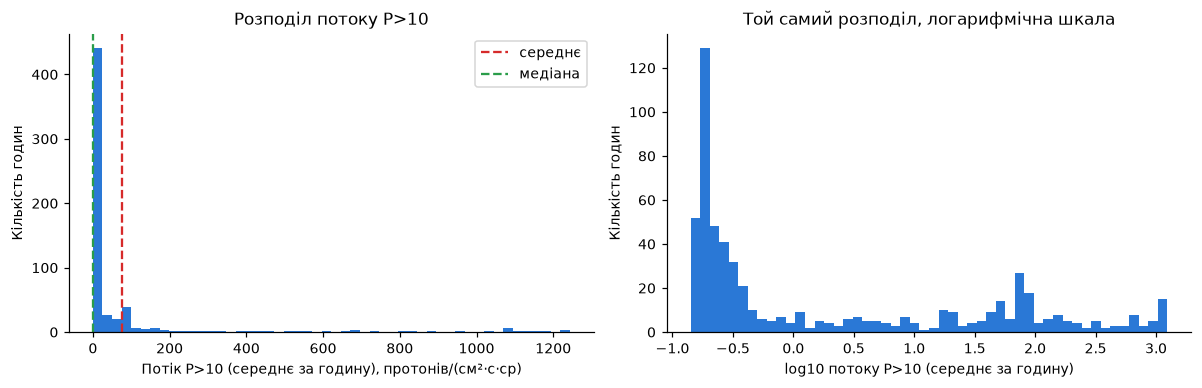

In [19]:
# ВАШ КОД
flux = завдання['ваш потік']
x = M[flux + '_mean'].dropna()
unit = ('протонів' if flux.startswith('P') else 'електронів') + '/(см²·с·ср)'

print('середнє: %.2f · медіана: %.3f · максимум: %.1f' % (x.mean(), x.median(), x.max()))
print('середнє / медіана: %.0f' % (x.mean() / x.median()))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))

ax[0].hist(x, bins=50, color='#2a78d6')
ax[0].axvline(x.mean(), color='#d62a2a', ls='--', label='середнє')
ax[0].axvline(x.median(), color='#2a9d4a', ls='--', label='медіана')
ax[0].set_xlabel('Потік %s (середнє за годину), %s' % (flux, unit))
ax[0].set_ylabel('Кількість годин')
ax[0].set_title('Розподіл потоку %s' % flux)
ax[0].legend()

ax[1].hist(np.log10(x), bins=50, color='#2a78d6')
ax[1].set_xlabel('log10 потоку %s (середнє за годину)' % flux)
ax[1].set_ylabel('Кількість годин')
ax[1].set_title('Той самий розподіл, логарифмічна шкала')

fig.tight_layout()
plt.show()


**Висновок:** Розподіл сильно скошений. Більшість годин мають потік близько 0,3, а кілька годин дають значення до 1243. Тому середнє (76,5) у ≈220 разів більше за медіану (0,34). Для такого розподілу медіана краще описує типову годину, а середнє визначають рідкісні бурі.

### Графік 2. Чи відрізняється швидкість вітру між групами годин?
Побудуйте діаграму розмаху (`boxplot`) швидкості сонячного вітру окремо для кожної
групи з завдання 4.4.

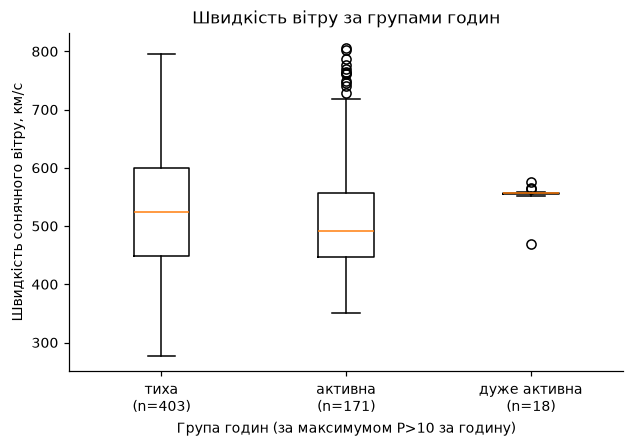

              count  median   mean    min    max
група                                           
тиха            403   524.0  511.3  277.0  795.0
активна         171   492.0  515.1  350.0  806.0
дуже активна     18   556.0  552.9  469.0  575.0


In [20]:
# ВАШ КОД
box_data = [M.loc[M['група'] == grp, 'speed'].dropna() for grp in group_order]

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.boxplot(box_data)
ax.set_xticks([1, 2, 3])
ax.set_xticklabels(['%s\n(n=%d)' % (grp, len(vals)) for grp, vals in zip(group_order, box_data)])
ax.set_xlabel('Група годин (за максимумом P>10 за годину)')
ax.set_ylabel('Швидкість сонячного вітру, км/с')
ax.set_title('Швидкість вітру за групами годин')
plt.show()

print(M.groupby('група', observed=True)['speed'].agg(['count', 'median', 'mean', 'min', 'max']).round(1).to_string())


**Висновок:** Швидкість вітру майже однакова в усіх групах (медіани 524, 492 і 556 км/с), ящики сильно перекриваються. За швидкістю не можна відрізнити тихі години від активних. У групі «дуже активна» лише 18 годин, тому її вузький ящик не варто вважати закономірністю.

### Графік 3. Чи пов'язані змінні вашої пари?
Побудуйте діаграму розсіювання для пари з вашого завдання. Порахуйте коефіцієнт
кореляції між ними.

Ваша пара: швидкість вітру та потік P>10
Пірсон: 0.071 · Спірмен: 0.247 · Пірсон з log10 потоку: 0.167 · n = 592


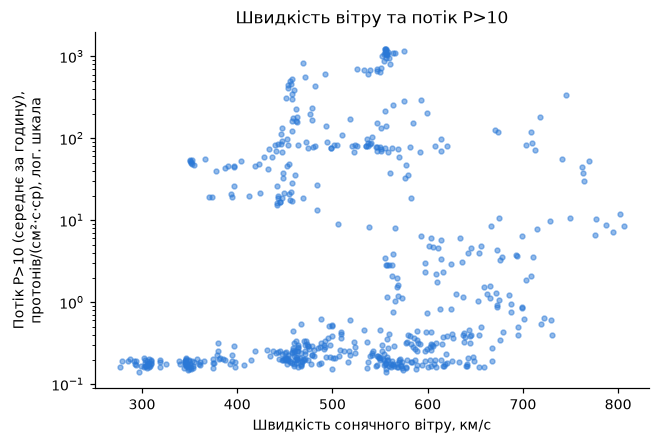

In [21]:
# ВАШ КОД
print('Ваша пара:', завдання['ваша пара для графіка 3'])

x_col, y_col = 'speed', flux + '_mean'
d = M[[x_col, y_col]].dropna()

r_pearson = d[x_col].corr(d[y_col])
r_spearman = d[x_col].corr(d[y_col], method='spearman')
r_log = d[x_col].corr(np.log10(d[y_col]))
print('Пірсон: %.3f · Спірмен: %.3f · Пірсон з log10 потоку: %.3f · n = %d'
      % (r_pearson, r_spearman, r_log, len(d)))

fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.scatter(d[x_col], d[y_col], s=10, alpha=0.5, color='#2a78d6')
ax.set_yscale('log')
ax.set_xlabel('Швидкість сонячного вітру, км/с')
ax.set_ylabel('Потік %s (середнє за годину),\nпротонів/(см²·с·ср), лог. шкала' % flux)
ax.set_title('Швидкість вітру та потік %s' % flux)
plt.show()


**Висновок:** Зв’язку між швидкістю вітру та потоком P>10 практично немає: Пірсон 0,07, Спірмен 0,25. Високі потоки (100–1000) трапляються при швидкості 350–750 км/с, а фон ≈0,2–0,5 є при будь-якій швидкості. Точки утворюють дві «хмари» (фон і буря), а не лінію. Це не доводить відсутності причинного зв’язку, лише те, що в цій вибірці він слабкий.

### Графік 4. Скільки годин у кожній групі?
Побудуйте стовпчикову діаграму кількості годин за групами. Підпишіть кожен стовпчик
кількістю годин і відсотком від загальної кількості.

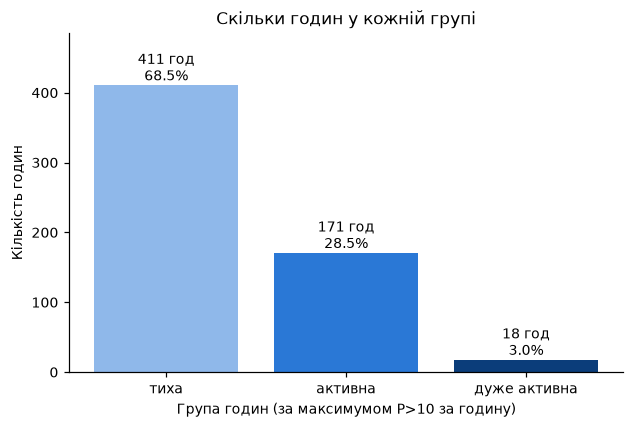

In [22]:
# ВАШ КОД
counts = M['група'].value_counts().reindex(group_order)
share = counts / counts.sum() * 100        # відсоток від годин, для яких група визначена

fig, ax = plt.subplots(figsize=(6.5, 4))
bars = ax.bar(group_order, counts.values, color=['#8fb8ea', '#2a78d6', '#0b3d7a'])
for s, n, p in zip(bars, counts, share):
    ax.text(s.get_x() + s.get_width() / 2, s.get_height(), '%d год\n%.1f%%' % (n, p),
            ha='center', va='bottom')
ax.set_ylim(0, counts.max() * 1.18)
ax.set_xlabel('Група годин (за максимумом P>10 за годину)')
ax.set_ylabel('Кількість годин')
ax.set_title('Скільки годин у кожній групі')
plt.show()


**Висновок:** Більшість часу було спокійно: тихих годин 411 (68,5%), активних 171 (28,5%), дуже активних лише 18 (3,0%). Сплески рідкісні, але саме вони дають основну частину потоку.

### Графік 5. Як усе це виглядало в часі?
Побудуйте лінійний графік максимуму потоку P>10 за годину за весь період спостережень.

Якщо крива виявиться нечитабельною — згадайте, що допомогло в графіку 1.

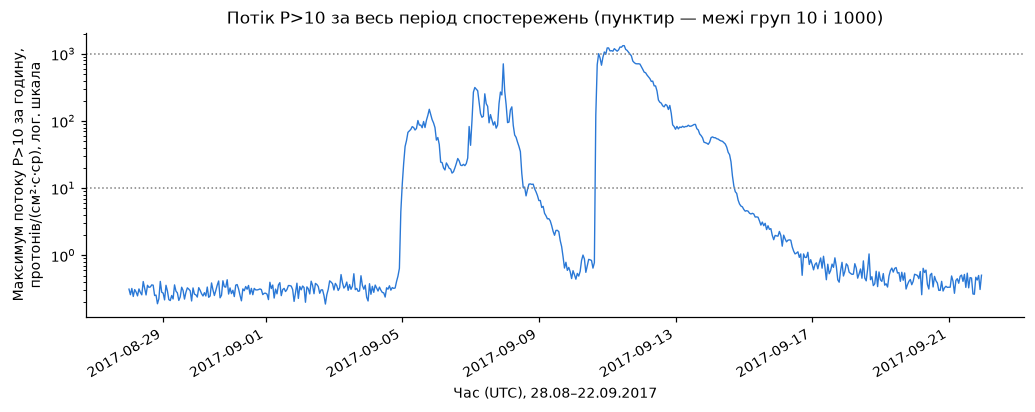

In [23]:
# ВАШ КОД
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(M['ts'], M['P>10_max'], color='#2a78d6', lw=0.9)
ax.set_yscale('log')
ax.axhline(10, color='gray', ls=':', lw=1)
ax.axhline(1000, color='gray', ls=':', lw=1)
ax.set_xlabel('Час (UTC), 28.08–22.09.2017')
ax.set_ylabel('Максимум потоку P>10 за годину,\nпротонів/(см²·с·ср), лог. шкала')
ax.set_title('Потік P>10 за весь період спостережень (пунктир — межі груп 10 і 1000)')
fig.autofmt_xdate()
plt.show()


**Висновок:** Потік тримається близько 0,3 до 5 вересня, тоді різко зростає більш ніж у 100 разів. Бура має дві хвилі з паузою 9–10 вересня й пік 11 вересня (1330), після чого поступово спадає до фону.

---
# Етап 6. Два графіки одних і тих самих даних

Нижче побудовано два графіки. Дані в них **одні й ті самі** — це той самий стовпець
з тієї самої таблиці, жодне число не змінено.

Виконайте клітинку й подивіться на обидва.

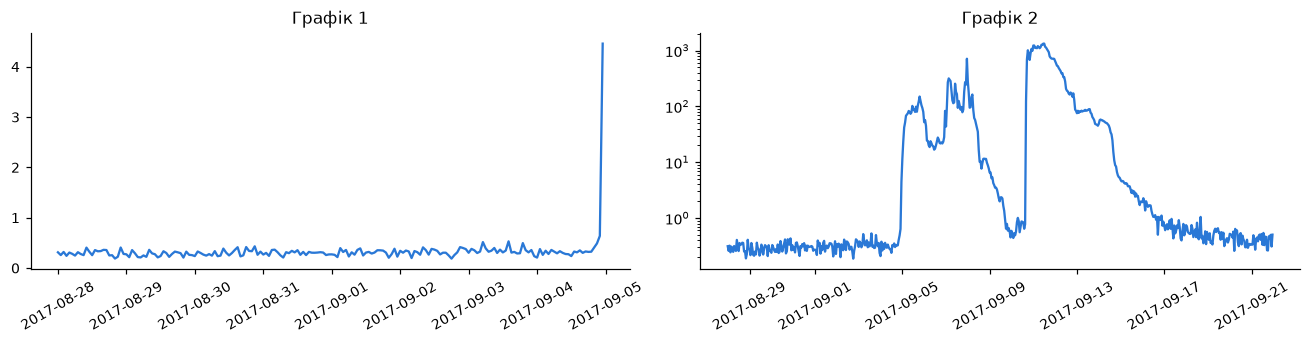

In [24]:
СТОВПЕЦЬ = 'P>10_max'   # <- впишіть назву свого стовпця з МАКСИМУМОМ P>10 за годину

вікно = M[(M['ts'] >= '2017-08-28') & (M['ts'] < '2017-09-05')]

fig, ax = plt.subplots(1, 2, figsize=(12, 3.2))

ax[0].plot(вікно['ts'], вікно[СТОВПЕЦЬ], color='#2a78d6')
ax[0].set_title('Графік 1')
ax[0].tick_params(axis='x', rotation=30)

ax[1].plot(M['ts'], M[СТОВПЕЦЬ], color='#2a78d6')
ax[1].set_yscale('log')
ax[1].set_title('Графік 2')
ax[1].tick_params(axis='x', rotation=30)

fig.tight_layout()
plt.show()

### Завдання 6.1
Дайте відповідь на три питання:

1. Який висновок про космічну погоду у вересні 2017 року зробить людина, яка бачила
   **тільки перший** графік?
2. Який висновок зробить людина, яка бачила **тільки другий**?
3. Чим ці два графіки відрізняються між собою? Назвіть **дві** відмінності —
   вони обидві є в коді вище.

*Жодне число в обох графіках не підроблене. Різниця виникла тільки через те,
як їх побудували.*

**Відповідь 6.1:**

1. Висновок з першого графіка: у період 28.08–04.09 потік P>10 стабільно низький (≈0,3), і лише наприкінці з’являється різкий стрибок. Складається враження спокійного періоду з раптовим стартом.
2. Висновок з другого графіка: на всьому періоді видно велику багатоденну бурю 5–14 вересня з двома хвилями й зростанням потоку у тисячі разів, а потім повернення до фону.
3. Дві відмінності між ними: (1) вікно часу — перший показує лише 8 діб, другий весь період; (2) шкала осі Y — лінійна на першому та логарифмічна на другому, через що на першому фон і бурю не видно разом.


### Завдання 6.2
Уявіть, що вам потрібно **одним графіком** чесно показати, що відбувалося в цьому
періоді. Побудуйте його самі й підпишіть заголовком, який формулює висновок.

Поясніть у клітинці нижче, чому ви обрали саме такий вигляд.

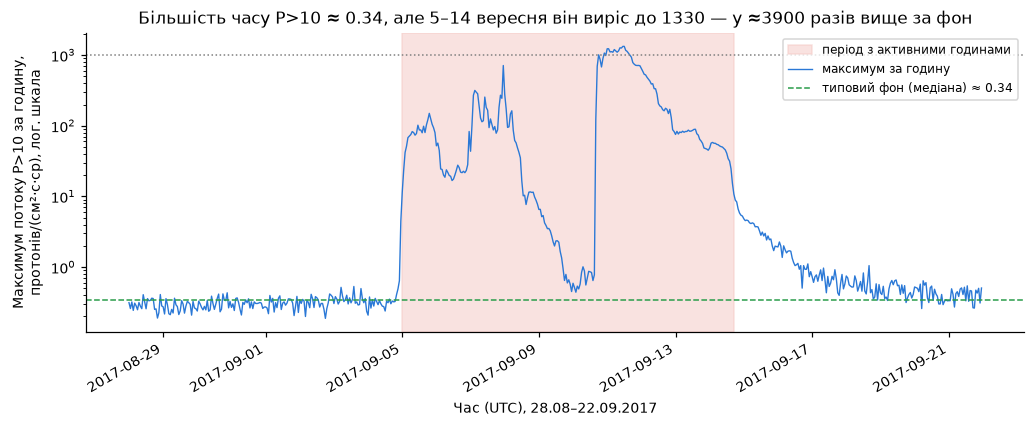

In [25]:
# ВАШ КОД
baseline = M['P>10_mean'].median()                  # типове значення «в спокої»
peak = M['P>10_max'].max()
active = M[M['P>10_max'] >= 10]               # години, що вийшли з групи «тиха»

fig, ax = plt.subplots(figsize=(11, 4))
ax.axvspan(active['ts'].min(), active['ts'].max(), color='#f4c7c3', alpha=0.5,
           label='період з активними годинами')
ax.plot(M['ts'], M['P>10_max'], color='#2a78d6', lw=0.9, label='максимум за годину')
ax.axhline(baseline, color='#2a9d4a', ls='--', lw=1, label='типовий фон (медіана) ≈ %.2f' % baseline)
ax.axhline(1000, color='gray', ls=':', lw=1)
ax.set_yscale('log')
ax.set_xlabel('Час (UTC), 28.08–22.09.2017')
ax.set_ylabel('Максимум потоку P>10 за годину,\nпротонів/(см²·с·ср), лог. шкала')
ax.set_title('Більшість часу P>10 ≈ %.2f, але %d–%d вересня він виріс до %d — у ≈%d разів вище за фон'
             % (baseline, active['ts'].min().day, active['ts'].max().day, peak, round(peak / baseline, -2)))
ax.legend(loc='upper right', fontsize=8)
fig.autofmt_xdate()
plt.show()


**Відповідь 6.2:** Я побудував лінію максимуму P>10 за весь період із логарифмічною віссю Y, лінією типового фону (медіана) та порогом 1000. Дані охоплюють кілька порядків величин, і на лінійній шкалі фон і початок бурі були б невидимі. Заголовок прямо формулює висновок, а підписи осей містять одиниці вимірювання.

---
# Етап 7. Три спостереження та ваше питання

### Завдання 7.1
Запишіть **три спостереження** про ці дані, які ви зробили під час роботи.

Спостереження — це твердження, яке спирається на конкретне число або графік з вашого
ноутбука. Не «дані цікаві», а, наприклад, «максимальне значення потоку у 2000 разів
більше за медіанне, і всі такі години припадають на одні й ті самі три доби».

Для кожного вкажіть, **де саме** у вашій роботі його видно.

**Спостереження 1:** Середнє P>10 за годину (76,5) у ≈220 разів більше за медіану (0,34). Видно в клітинці з графіком 1 (етап 5).

**Спостереження 2:** Усі 189 активних годин (171 «активна» + 18 «дуже активна») лежать у межах 5–14 вересня, а до 5 вересня потік стабільно ≈0,3. Видно на графіках 4 і 5 (етап 5).

**Спостереження 3:** У таблиці C 8 годин поспіль (4 вересня, 07:00–14:00) мають `-1` замість значень, а таблиці закінчуються в різний момент (inner 600 рядків проти outer 601). Видно у завданнях 3.2 і 4.3.


### Завдання 7.2 — ваше індивідуальне питання
Дайте відповідь на додаткове питання зі свого завдання. Відповідь має спиратися
на обчислення: наведіть код і результат, а потім сформулюйте висновок словами.

In [26]:
# ВАШ КОД
flux = завдання['ваш потік']

# одна доба = один рядок: F10.7 (вона й так добова) та найбільший максимум потоку за добу
daily = (M.assign(day=M['ts'].dt.normalize())
          .groupby('day')
          .agg(F107=('F107', 'first'), max_flux=(flux + '_max', 'max'))
          .dropna())
print(daily.to_string())

day_f107 = daily['F107'].idxmax()
day_peak = daily['max_flux'].idxmax()
print()
print('F10.7 найбільший: %s (%d)' % (day_f107.date(), daily.loc[day_f107, 'F107']))
print('пік потоку %s: %s (%.0f)' % (flux, day_peak.date(), daily.loc[day_peak, 'max_flux']))
print('збігаються:', day_f107 == day_peak, '· різниця у добах:', (day_peak - day_f107).days)
print('кореляція Спірмена F10.7 і добового максимуму потоку: %.2f'
      % daily['F107'].corr(daily['max_flux'], method='spearman'))


             F107  max_flux
day                        
2017-08-28   82.0     0.409
2017-08-29   84.0     0.363
2017-08-30   87.0     0.433
2017-08-31   92.0     0.367
2017-09-01   93.0     0.397
2017-09-02  100.0     0.417
2017-09-03  120.0     0.532
2017-09-04  140.0     4.460
2017-09-05  121.0   150.000
2017-09-06  133.0    83.100
2017-09-07  129.0   713.000
2017-09-08  117.0   279.000
2017-09-09  107.0     6.570
2017-09-10  100.0  1070.000
2017-09-11   80.0  1330.000
2017-09-12   76.0   648.000
2017-09-13   75.0    89.300
2017-09-14   74.0    58.200
2017-09-15   73.0     4.830
2017-09-16   72.0     2.270
2017-09-17   72.0     0.969
2017-09-18   72.0     1.050
2017-09-19   71.0     0.658
2017-09-20   74.0     0.641
2017-09-21   73.0     0.543

F10.7 найбільший: 2017-09-04 (140)
пік потоку P>10: 2017-09-11 (1330)
збігаються: False · різниця у добах: 7
кореляція Спірмена F10.7 і добового максимуму потоку: 0.18


**Відповідь 7.2:** Радіопотік F10.7 був найбільшим **4 вересня 2017** (140), а пік потоку P>10 припав на **11 вересня 2017** (1330 за максимумом за годину). Дні **не збігаються**, різниця — 7 діб. Кореляція Спірмена між добовими значеннями F10.7 та добовим максимумом P>10 лише 0,18, тобто в цих даних зв’язок практично відсутній.

---
# Етап 8. Декларація про використання інструментів штучного інтелекту

Користуватися мовними моделями під час виконання цієї роботи **дозволено**. Це
нормальна інженерна практика, і курс про штучний інтелект не має підстав її забороняти.

Обов'язковою є прозорість: ви вказуєте, де саме і як скористалися інструментом —
так само, як у науковій статті вказують використане програмне забезпечення.
**Задекларована допомога порушенням не є.**

Порушенням є інше: здати роботу, яку ви не можете пояснити. На захисті вас попросять
показати конкретний рядок вашого коду, пояснити, чому він саме такий, і внести в нього
невелику зміну на місці. Якщо код згенеровано, але ви його розумієте — робота
зарахована. Якщо не розумієте — не зарахована, незалежно від того, хто його написав.

### Завдання 8.1
Заповніть словник. Для кожного етапу оберіть одне з формулювань:

* `'ні'` — інструментами ШІ не користувався;
* `'синтаксис'` — питав про назву функції або синтаксис, код писав сам;
* `'код, перевірено'` — код згенеровано, я його прочитав, перевірив і розумію;
* `'текст, перероблено'` — згенеровано чернетку тексту, яку я переписав по суті;
* `'текст, як є'` — згенерований текст залишено майже без змін.

Останній варіант не заборонений, але прямо впливає на оцінку: бали ставляться
за висновки, а не за наявність абзацу.

In [27]:
ІНСТРУМЕНТИ_ШІ = 'Clode'     # напр. 'ChatGPT' або 'не використовував'

ДЕКЛАРАЦІЯ = {
    'етапи 1–2, читання файлу та розбір таблиць': 'код, перевірено',
    'етап 3, паспорт даних і дивні значення':     'код, перевірено',
    'етап 4, об’єднання таблиць':                 'код, перевірено',
    'етап 5, побудова графіків':                  'код, перевірено',
    'етап 5, формулювання висновків':             'код, перевірено',
    'етапи 6–7, порівняння графіків і спостереження': 'код, перевірено',
}

# Що саме ви перевірили за згенерованим кодом чи текстом — конкретно:
# які числа звірили, що переписали, де знайшли помилку.
ЩО_ПЕРЕВІРЕНО = 'Перевірив код на відповідність вимогам завдань, прочитав кожну клітинку і розумію, що вона робить та як отримано результат.'

# True означає: я можу пояснити кожен рядок свого коду, відтворити будь-який
# результат цієї роботи та внести зміни в код на вимогу під час захисту.
ПІДТВЕРДЖУЮ = True

In [28]:
# --- перевірка повноти декларації: клітинку не редагувати --------------------
ДОЗВОЛЕНІ = {'ні', 'синтаксис', 'код, перевірено', 'текст, перероблено', 'текст, як є'}

assert ІНСТРУМЕНТИ_ШІ.strip(), 'Вкажіть інструменти або напишіть «не використовував»'
порожні = [k for k, v in ДЕКЛАРАЦІЯ.items() if not str(v).strip()]
assert not порожні, 'Не заповнено пункти декларації: %s' % '; '.join(порожні)
чужі = {v for v in ДЕКЛАРАЦІЯ.values() if v not in ДОЗВОЛЕНІ}
assert not чужі, 'Недопустимі значення: %s. Оберіть з переліку вище.' % ', '.join(sorted(чужі))
assert len(ЩО_ПЕРЕВІРЕНО.strip()) >= 120, ('Опишіть конкретніше, що саме ви перевірили '
                                           '(зараз %d символів, потрібно щонайменше 120)'
                                           % len(ЩО_ПЕРЕВІРЕНО.strip()))
assert ПІДТВЕРДЖУЮ is True, 'Підтвердьте, що можете пояснити власний код на захисті'

print('ДЕКЛАРАЦІЯ ПРО ВИКОРИСТАННЯ ІНСТРУМЕНТІВ ШІ')
print('=' * 78)
print('%-46s %s' % ('автор:', ПІБ))
print('%-46s %s' % ('інструменти:', ІНСТРУМЕНТИ_ШІ))
print('-' * 78)
for k, v in ДЕКЛАРАЦІЯ.items():
    print('%-46s %s' % (k + ':', v))
print('-' * 78)
print('перевірено автором:')
print(ЩО_ПЕРЕВІРЕНО)
print('=' * 78)
print('Автор підтверджує, що може пояснити кожен рядок коду під час захисту.')

ДЕКЛАРАЦІЯ ПРО ВИКОРИСТАННЯ ІНСТРУМЕНТІВ ШІ
автор:                                         Яцишин Роман Олегович
інструменти:                                   Clode
------------------------------------------------------------------------------
етапи 1–2, читання файлу та розбір таблиць:    код, перевірено
етап 3, паспорт даних і дивні значення:        код, перевірено
етап 4, об’єднання таблиць:                    код, перевірено
етап 5, побудова графіків:                     код, перевірено
етап 5, формулювання висновків:                код, перевірено
етапи 6–7, порівняння графіків і спостереження: код, перевірено
------------------------------------------------------------------------------
перевірено автором:
Перевірив код на відповідність вимогам завдань, прочитав кожну клітинку і розумію, що вона робить та як отримано результат.
Автор підтверджує, що може пояснити кожен рядок коду під час захисту.


---
# Крок 9. Збереження результату та фінальна самоперевірка

Об'єднана таблиця знадобиться вам у лабораторних роботах № 3 і № 4 — збережіть її
й не втрачайте до кінця семестру.

In [29]:
M.to_csv('master_hourly.csv', index=False)
print('збережено:', M.shape)

збережено: (601, 21)


In [30]:
# --- фінальна самоперевірка --------------------------------------------------
перевірки = {
    'ПІБ і варіант заповнено':        bool(ПІБ) and bool(ВАРІАНТ),
    'таблиця A (7200 рядків)':        len(A) == 7200,
    'таблиця B (25 рядків)':          len(B) == 25,
    'таблиця C (601 рядок)':          len(C) == 601,
    'таблиці об’єднано':              M is not None and 590 <= len(M) <= 605,
    'стовпець «група» є':             'група' in M.columns,
    'усі дати у 2017 році':           int(pd.to_datetime(M['ts']).dt.year.min()) == 2017,
    'декларацію заповнено':           bool(ІНСТРУМЕНТИ_ШІ.strip()) and ПІДТВЕРДЖУЮ is True,
}
for k, v in перевірки.items():
    print(('OK   ' if v else 'НЕ ОК') + '  ' + k)

if all(перевірки.values()):
    print('\nТехнічна частина роботи виконана.')
    print('Тепер переконайтеся, що заповнені ВСІ клітинки з відповідями та висновками,')
    print('і виконайте Kernel → Restart & Run All перед здачею.')

OK     ПІБ і варіант заповнено
OK     таблиця A (7200 рядків)
OK     таблиця B (25 рядків)
OK     таблиця C (601 рядок)
OK     таблиці об’єднано
OK     стовпець «група» є
OK     усі дати у 2017 році
OK     декларацію заповнено

Технічна частина роботи виконана.
Тепер переконайтеся, що заповнені ВСІ клітинки з відповідями та висновками,
і виконайте Kernel → Restart & Run All перед здачею.
